# Imports 

In [1]:
import sys
import random

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

import torch 
from torch import nn, optim 
from torch.utils.data import Dataset, DataLoader 

from torchvision import transforms as T

import timm

sys.path.insert(0, '..')  # repo root, for utils/

![](../media/sample-spectrograms.jpg)

# Configurations

In [2]:
TRAIN_CSV = '../data/train.csv'
VALID_CSV = '../data/valid.csv'

BATCH_SIZE = 128
DEVICE = 'cpu'

MODEL_NAME = 'efficientnet_b0'

LR = 0.001
EPOCHS = 10
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED);

In [3]:
df_train = pd.read_csv(TRAIN_CSV)
df_valid = pd.read_csv(VALID_CSV)

df_train.head()

,0,1,2,3,4,5,6,7,8,9,...,8183,8184,8185,8186,8187,8188,8189,8190,8191,labels
0,0.631373,0.623529,0.713726,0.705882,0.658824,0.666667,0.654902,0.635294,0.647059,0.705882,...,0.611765,0.650980,0.658824,0.600000,0.603922,0.654902,0.694118,0.658824,0.666667,Squiggle
1,0.725490,0.752941,0.749020,0.701961,0.690196,0.721569,0.709804,0.745098,0.654902,0.721569,...,0.698039,0.721569,0.686275,0.713726,0.682353,0.690196,0.698039,0.701961,0.725490,Squiggle
2,0.717647,0.701961,0.713726,0.733333,0.705882,0.717647,0.725490,0.682353,0.717647,0.674510,...,0.694118,0.705882,0.682353,0.639216,0.713726,0.670588,0.678431,0.737255,0.674510,Squiggle
3,0.705882,0.674510,0.654902,0.678431,0.666667,0.662745,0.678431,0.662745,0.686275,0.686275,...,0.662745,0.631373,0.643137,0.705882,0.662745,0.705882,0.666667,0.654902,0.631373,Squiggle
4,0.647059,0.729412,0.701961,0.674510,0.611765,0.698039,0.713726,0.662745,0.701961,0.674510,...,0.670588,0.705882,0.674510,0.721569,0.694118,0.674510,0.705882,0.749020,0.729412,Squiggle


In [4]:
print(f"No. of examples present in df_train : {len(df_train)}")
print(f"No. of examples present in df_valid : {len(df_valid)}")
print(f"Labels are : {df_train['labels'].unique()}")

No. of examples present in df_train : 3200
No. of examples present in df_valid : 800
Labels are : <StringArray>
['Squiggle', 'Narrowbanddrd', 'Noises', 'Narrowband']
Length: 4, dtype: str


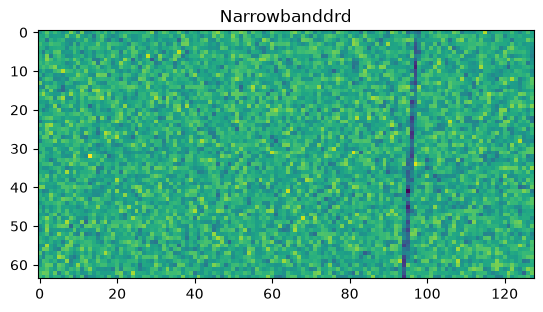

In [5]:
idx = 900
row = df_train.iloc[idx]

image_pixels = np.array(row.iloc[:8192], dtype=np.float64)
label = row.labels

image = np.resize(image_pixels, (64, 128))  # 64 * 128 = 8192

plt.imshow(image)
plt.title(label);

# Declare Spec Augmentations 

![](../media/specaugment-sample.png)

In [6]:
from utils.spec_augment import TimeMask, FreqMask

In [7]:
def get_train_tranform():
    return T.Compose([
        TimeMask(T = 15, num_masks = 4),
        FreqMask(F = 15, num_masks = 4)
    ])

# Create Custom Dataset 

In [8]:
class SpecDataset(Dataset):
    def __init__(self, df, augs = None):
        self.df = df.copy()
        self.augs = augs
        
        label_map = {
            'Squiggle': 0,
            'Narrowbanddrd': 1,
            'Noises': 2,
            'Narrowband': 3
        }
        self.df['labels'] = self.df.labels.map(label_map)
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_pixels = np.array(row.iloc[:8192], dtype=np.float64)
        
        image = np.resize(image_pixels, (64, 128, 1)) # (h, w, c)
        label = np.array(row.labels, dtype=np.int64)
        
        image = torch.Tensor(image).permute(2, 0, 1)# (c, h, w)
        
        if self.augs is not None:
            image = self.augs(image)
            
        return image.float(), label

In [9]:
trainset   = SpecDataset(df_train, augs=get_train_tranform())
validset   = SpecDataset(df_valid)

0


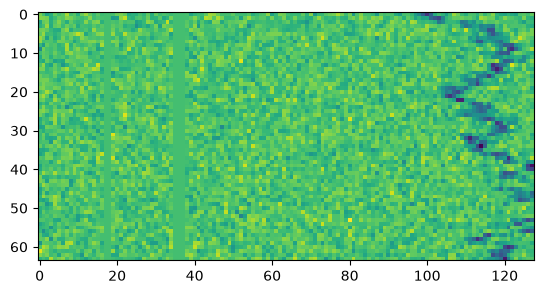

In [10]:
image, label = trainset[400]

plt.imshow(image.permute(0, 1, 2).squeeze())
print(label)

# Load dataset into Batches

In [11]:
trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True)
validloader = DataLoader(validset, batch_size=BATCH_SIZE)

In [12]:
print(f"Total no. of batches in trainloader : {len(trainloader)}")
print(f"Total no. of batches in validloader : {len(validloader)}")

Total no. of batches in trainloader : 25
Total no. of batches in validloader : 7


In [13]:
for images, labels in trainloader:
    break

print(f"One image batch shape : {images.shape}")
print(f"One label batch shape : {labels.shape}")

One image batch shape : torch.Size([128, 1, 64, 128])
One label batch shape : torch.Size([128])


# Load Model

In [14]:
# List Models with Pretrained Weights
avail_pretrained_models = timm.list_models(pretrained=True)
len(avail_pretrained_models), avail_pretrained_models[490:500]

(1807,
 ['focalnet_base_srf.ms_in1k',
  'focalnet_huge_fl3.ms_in22k',
  'focalnet_huge_fl4.ms_in22k',
  'focalnet_large_fl3.ms_in22k',
  'focalnet_large_fl4.ms_in22k',
  'focalnet_small_lrf.ms_in1k',
  'focalnet_small_srf.ms_in1k',
  'focalnet_tiny_lrf.ms_in1k',
  'focalnet_tiny_srf.ms_in1k',
  'focalnet_xlarge_fl3.ms_in22k'])

In [15]:
# Search for model architectures by Wildcard
all_densenet_models = timm.list_models('*inception*')
all_densenet_models

['inception_next_atto',
 'inception_next_base',
 'inception_next_small',
 'inception_next_tiny',
 'inception_resnet_v2',
 'inception_v3',
 'inception_v4']

In [16]:
class SpecModel(nn.Module):
    def __init__(self):
        super(SpecModel, self).__init__()
        
        self.net = timm.create_model(MODEL_NAME, num_classes = 4, pretrained = True, in_chans=1)
        
    def forward(self, images, labels = None):
        logits = self.net(images)
        
        if labels is not None:
            loss = nn.CrossEntropyLoss()
            return logits, loss(logits, labels)
        
        return logits

In [17]:
model = SpecModel()
model

SpecModel(
  (net): EfficientNet(
    (conv_stem): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (bn1): BatchNormAct2d(
            32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
            (drop): Identity()
            (act): SiLU(inplace=True)
          )
          (aa): Identity()
          (se): SqueezeExcite(
            (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (act1): SiLU(inplace=True)
            (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (gate): Sigmoid()
          )
       

# Create Train and Eval Function

In [18]:
from tqdm.notebook import tqdm 
from utils.utils import multiclass_accuracy

In [19]:
def train_fn(model, dataloader, optimizer, current_epoch):
    
    model.train()
    total_loss = 0.0
    total_acc = 0.0
    progress_bar = tqdm(dataloader, desc="EPOCH" + "[TRAIN]" + str(current_epoch+1) + '/' + str(EPOCHS))
    
    for t, data in enumerate(progress_bar):
        images, labels = data
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        
        #print("Labels:", labels)
        #print("Labels shape:", labels.shape)
        
        optimizer.zero_grad()
        logits, loss = model(images, labels)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        total_acc += multiclass_accuracy(logits, labels)
        
        temp = {'loss': '%6f' %float(total_loss/ (t+1)), 'acc': '%6f' %float(total_acc/ (t+1))}
        progress_bar.set_postfix(temp)
        
    return total_loss/len(dataloader), float(total_acc/len(dataloader))

In [20]:
def eval_fn(model, dataloader, current_epoch):
    
    model.eval()
    total_loss = 0.0
    total_acc = 0.0
    progress_bar = tqdm(dataloader, desc="EPOCH" + "[VALID]" + str(current_epoch+1) + '/' + str(EPOCHS))
    
    with torch.no_grad():
        for t, data in enumerate(progress_bar):
            images, labels = data
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            logits, loss = model(images, labels)

            total_loss += loss.item()
            total_acc  += multiclass_accuracy(logits, labels)

            temp = {'loss': '%6f' %float(total_loss/ (t+1)), 'acc': '%6f' %float(total_acc/ (t+1))}
            progress_bar.set_postfix(temp)
        
    return total_loss/len(dataloader), float(total_acc/len(dataloader))

# Training Loop 

In [21]:
def fit(model, trainloader, validloader, optimizer):
    
    best_valid_loss = np.inf
    history = []
    
    for i in range(EPOCHS):
        train_loss, train_acc = train_fn(model, trainloader, optimizer, i)
        valid_loss, valid_acc = eval_fn(model, validloader, i)
        history.append({'epoch': i + 1, 'train_loss': train_loss, 'train_acc': train_acc,
                        'valid_loss': valid_loss, 'valid_acc': valid_acc})
        print(f"epoch {i+1}: train loss {train_loss:.4f} acc {train_acc:.4f} | valid loss {valid_loss:.4f} acc {valid_acc:.4f}")
        
        if valid_loss < best_valid_loss:
            torch.save(model.state_dict(), MODEL_NAME + "-best-weights.pt")
            print("SAVED BEST WEIGHTS")
            best_valid_loss = valid_loss
            
    return history

In [22]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
history = fit(model, trainloader, validloader, optimizer)

epoch 1: train loss 1.1680 acc 0.7022 | valid loss 15.3511 acc 0.2232
SAVED BEST WEIGHTS


epoch 2: train loss 0.4396 acc 0.7487 | valid loss 1.5146 acc 0.5279
SAVED BEST WEIGHTS


epoch 3: train loss 0.3864 acc 0.7544 | valid loss 0.7355 acc 0.7031
SAVED BEST WEIGHTS


epoch 4: train loss 0.3646 acc 0.7628 | valid loss 0.3998 acc 0.7232
SAVED BEST WEIGHTS


epoch 5: train loss 0.3605 acc 0.7725 | valid loss 0.3832 acc 0.7746
SAVED BEST WEIGHTS


epoch 6: train loss 0.3660 acc 0.7669 | valid loss 0.4017 acc 0.7277


epoch 7: train loss 0.3532 acc 0.7759 | valid loss 0.4210 acc 0.7679


epoch 8: train loss 0.3735 acc 0.7638 | valid loss 0.4394 acc 0.7121


epoch 9: train loss 0.3597 acc 0.7744 | valid loss 0.4466 acc 0.7098


epoch 10: train loss 0.3541 acc 0.7891 | valid loss 0.5030 acc 0.6987


# Inference 

In [23]:
from dataset.dataset import CLASSES  # label order used by SpecDataset
from utils.utils import view_classify, confusion_matrix, plot_confusion_matrix

model.load_state_dict(torch.load(MODEL_NAME + "-best-weights.pt"))
model.eval();

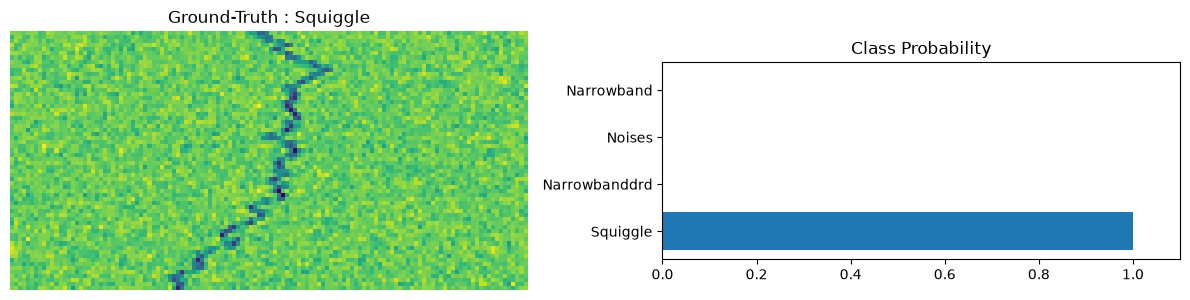

In [24]:
image, label = validset[23]

with torch.no_grad():
    logits = model(image.unsqueeze(0))  # (c, h, w) -> (1, c, h, w)
    ps = torch.softmax(logits, dim=1)

view_classify(image.squeeze(), ps, true_label=CLASSES[int(label)])

validation accuracy of the best weights: 0.7550


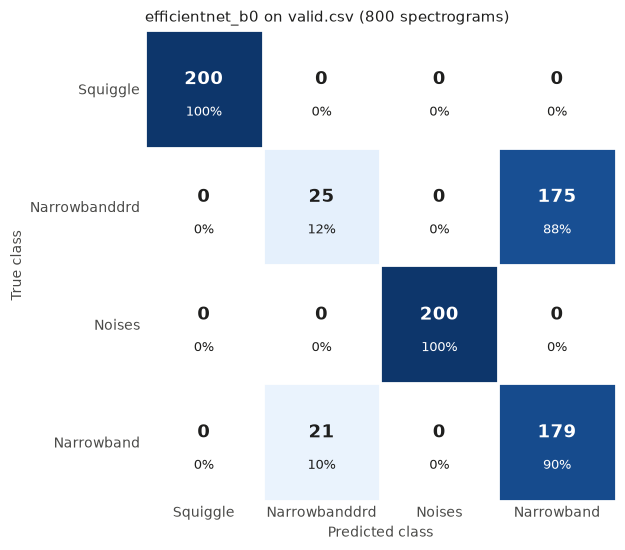

In [25]:
y_true, y_pred = [], []
with torch.no_grad():
    for images, labels in validloader:
        logits = model(images.to(DEVICE))
        y_true.extend(labels.tolist())
        y_pred.extend(logits.argmax(dim=1).tolist())

y_true, y_pred = np.array(y_true), np.array(y_pred)
print(f"validation accuracy of the best weights: {(y_true == y_pred).mean():.4f}")

cm = confusion_matrix(y_true, y_pred)
plot_confusion_matrix(cm, title=f'{MODEL_NAME} on valid.csv ({len(y_true)} spectrograms)');